# 01 — EDA e preparação do bootstrap dataset

**Entregável:** análise exploratória (EDA) do *bootstrap dataset*, etapas de preparação (limpeza, tratamento de ausentes, transformação, normalização, codificação) e justificativa das principais decisões, com registro no **MLflow**.

## O que é o bootstrap dataset
`processed/dataset_ml_bairro_dia_completo.csv`: uma linha por **bairro × dia** (2014–2021), 45 colunas. Foi montado a partir de quatro fontes:

| Bloco | Fonte | Colunas |
|---|---|---|
| Alvo e histórico | Defesa Civil do Recife (atendimentos 2014–2024) | `alagou`, `alagou_estrito`, `n_alag_*`, `dias_desde_*` |
| Chuva | INMET, estação A301 (Recife), horária | `chuva_*` |
| Maré | Previsão astronômica (análise harmônica da série UHSLC 1955–1968) | `mare_*` |
| Local | Limites de bairros, faixas marginais e elevação (Copernicus, ~90 m) | `area_km2`, `alt_*`, `pct_*`, `dist_*` |

**Pergunta de modelagem:** dado o bairro e as condições do dia, qual a probabilidade de haver alagamento? O alvo principal é `alagou_estrito` (registro de "Alagamentos"/"Imóveis Alagados"); `alagou` (amplo) é o secundário.

## Como este notebook se encaixa no pipeline
A lógica de preparação está em `src/preparacao.py` (não repetida aqui), para que **treino, DAG do Airflow e API de inferência usem exatamente o mesmo código**. O notebook importa o módulo, explica cada decisão e mostra a evidência.

**Como rodar:** `pip3 install -r requirements-ml.txt`. O MLflow grava em um banco SQLite local (`mlflow.db`); para abrir a interface: `mlflow ui --backend-store-uri sqlite:///<caminho>/mlflow.db`. Para usar um servidor MLflow (ex.: o do Docker Compose), defina a variável de ambiente `MLFLOW_TRACKING_URI` antes de abrir o notebook.

## 1. Configuração e MLflow
Abrimos uma *run* do MLflow que acompanha o notebook inteiro: parâmetros (tamanho, período, hash do arquivo), métricas de qualidade, figuras e artefatos (relatórios em CSV/JSON). O **hash do arquivo** identifica a versão exata dos dados usada.

In [1]:
import os, sys, json, hashlib, warnings, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
from sklearn.metrics import roc_auc_score, average_precision_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 60); pd.set_option("display.max_rows", 100)

candidatos = [pathlib.Path("..").resolve(), pathlib.Path(".").resolve(), pathlib.Path("/Users/nhffbs/dados_alagamento")]
RAIZ = next(p for p in candidatos if (p / "processed" / "dataset_ml_bairro_dia_completo.csv").exists())
sys.path.insert(0, str(RAIZ / "src"))
import importlib, preparacao as prep
importlib.reload(prep)

DATA_PATH = RAIZ / "processed" / "dataset_ml_bairro_dia_completo.csv"
FIG_DIR = RAIZ / "relatorio_figuras"; FIG_DIR.mkdir(exist_ok=True)
ART_DIR = RAIZ / "processed" / "eda_artefatos"; ART_DIR.mkdir(exist_ok=True)

mlflow.set_tracking_uri(os.getenv("MLFLOW_TRACKING_URI", f"sqlite:///{RAIZ / 'mlflow.db'}"))
mlflow.set_experiment("alagamento_eda_preparacao")
if mlflow.active_run():
    mlflow.end_run()
run = mlflow.start_run(run_name="eda_bootstrap_dataset")
mlflow.set_tags({"etapa": "eda_preparacao", "dataset": DATA_PATH.name})

def registrar_fig(fig, nome):
    fig.savefig(FIG_DIR / f"{nome}.png", dpi=130, bbox_inches="tight")
    mlflow.log_figure(fig, f"figuras/{nome}.png")
    plt.show()

def registrar_arquivo(obj, nome):
    caminho = ART_DIR / nome
    if nome.endswith(".json"):
        caminho.write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
    else:
        obj.to_csv(caminho)
    mlflow.log_artifact(str(caminho), artifact_path="relatorios")

print("raiz:", RAIZ, "| tracking:", mlflow.get_tracking_uri(), "| run:", run.info.run_id)

/Users/nhffbs/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
2026/10/26 20:55:16 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/26 20:55:16 INFO mlflow.store.db.utils: Updating database tables
INFO  [alembic.runtime.migration] Context impl SQLiteImpl.
INFO  [alembic.runtime.migration] Will assume non-transactional DDL.
INFO  [alembic.runtime.migration] Context impl SQLiteImpl.
INFO  [alembic.runtime.migration] Will assume non-transactional DDL.


raiz: /Users/nhffbs/dados_alagamento | tracking: sqlite:////Users/nhffbs/dados_alagamento/mlflow.db | run: 5bc45d6bf0884a0fb1139fb990d3b46f


## 2. Visão geral do dataset
Carregamos o CSV, conferimos tipos e período, e registramos a identidade da versão dos dados no MLflow.

In [2]:
df = prep.carregar_dataset(DATA_PATH)
sha = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()[:16]

mlflow.log_params({
    "dataset_arquivo": DATA_PATH.name, "dataset_sha256_16": sha,
    "n_linhas": len(df), "n_colunas_originais": df.shape[1] - 1,
    "periodo_inicio": str(df["data"].min().date()), "periodo_fim": str(df["data"].max().date()),
    "n_bairros": df["bairro"].nunique(),
})
print(f"{len(df):,} linhas | {df.shape[1]-1} colunas | {df['data'].min().date()} a {df['data'].max().date()} | {df['bairro'].nunique()} bairros | sha256[:16]={sha}")

resumo = pd.DataFrame({"tipo": df.dtypes.astype(str), "vazio_%": (df.isna().mean() * 100).round(2), "valores_unicos": df.nunique()})
display(resumo)

227,916 linhas | 45 colunas | 2014-01-01 a 2021-12-31 | 78 bairros | sha256[:16]=f5440b6a1be3c2cb


,tipo,vazio_%,valores_unicos
bairro,object,0.00,78
regional,object,1.28,6
data,datetime64[ns],0.00,2922
alagou,int64,0.00,2
n_registros_alag,int64,0.00,44
chuva_dia_mm,float64,3.52,225
chuva_max_1h_mm,float64,3.52,122
horas_validas_dia,int64,0.00,21
chuva_d1_mm,float64,3.52,225
chuva_ult3d_mm,float64,3.42,406


### Dicionário de variáveis
Cada coluna tem um **papel** (chave, alvo, feature, controle de qualidade ou vazamento). As colunas marcadas como *vazamento* contam o próprio alvo do dia e **não podem** ser usadas como variáveis explicativas.

In [3]:
dic = pd.read_csv(RAIZ / "dicionario_variaveis.csv")
display(dic[dic["status"] == "no_dataset"][["variavel", "grupo", "papel_no_modelo", "unidade", "descricao", "preenchimento_pct"]].reset_index(drop=True))

,variavel,grupo,papel_no_modelo,unidade,descricao,preenchimento_pct
0,bairro,chave,chave,-,Nome do bairro/localidade (grafia mais frequen...,100.0
1,regional,contexto,feature categorica,-,Regional da Defesa Civil (moda por bairro),98.7
2,data,chave,chave,aaaa-mm-dd,Dia (horario local) do ponto de dados,100.0
3,alagou,alvo,alvo (rotulo amplo),-,1 se ha registro com 'alag' em Ocorrencia OU S...,100.0
4,n_registros_alag,vazamento,NAO USAR COMO FEATURE,-,Numero de registros de alagamento (amplo) no b...,100.0
5,chuva_dia_mm,chuva,feature (observada no dia),mm,Chuva acumulada no dia local (A301),96.5
6,chuva_max_1h_mm,chuva,feature (observada no dia),mm/h,Maior intensidade horaria do dia,96.5
7,horas_validas_dia,controle,controle de qualidade,h,Horas com medicao valida da A301 no dia (0-24),100.0
8,chuva_d1_mm,chuva,feature (antecedente),mm,Chuva do dia anterior,96.5
9,chuva_ult3d_mm,chuva,feature (antecedente),mm,Chuva acumulada nos 3 dias anteriores (D-3..D-1),96.6


## 3. Qualidade e integridade
Quatro verificações: (1) duplicatas, (2) valores fisicamente impossíveis, (3) consistência dos alvos (todo evento estrito deve ser também amplo) e (4) se a grade bairro × dia está completa.

In [4]:
qualidade = prep.verificar_qualidade(df)
print(json.dumps(qualidade, indent=2, ensure_ascii=False))

dias_esperados = (df["data"].max() - df["data"].min()).days + 1
dias_por_bairro = df.groupby("bairro")["data"].nunique()
print(f"\ndias esperados por bairro: {dias_esperados} | min/max observado: {dias_por_bairro.min()} / {dias_por_bairro.max()}")
print("grade completa:", bool((dias_por_bairro == dias_esperados).all()))

qualidade["grade_completa"] = bool((dias_por_bairro == dias_esperados).all())
registrar_arquivo(qualidade, "qualidade.json")
mlflow.log_metrics({"duplicatas": qualidade["duplicatas_bairro_data"],
                    "estrito_sem_amplo": qualidade.get("estrito_sem_amplo", 0),
                    "valores_fora_limite_total": sum(qualidade["valores_fora_do_limite"].values())})

{
  "linhas": 227916,
  "duplicatas_bairro_data": 0,
  "valores_fora_do_limite": {
    "chuva_dia_mm": 0,
    "chuva_max_1h_mm": 0,
    "mare_max_dia_m": 0,
    "mare_min_dia_m": 0,
    "alt_media_m": 0,
    "pct_pontos_abaixo_5m": 0,
    "pct_area_faixa_marginal": 0,
    "fase_lunar": 0
  },
  "alvo_fora_de_0_1": 0,
  "estrito_sem_amplo": 0
}

dias esperados por bairro: 2922 | min/max observado: 2922 / 2922
grade completa: True


**Leitura:** zero duplicatas, zero valores fora dos limites, nenhum evento estrito sem o amplo correspondente e grade completa significam que a **estrutura** dos dados está íntegra. Os problemas que restam são de **conteúdo** (ausentes, raridade do alvo, cobertura de chuva), tratados abaixo.

## 4. Valores ausentes: nem todo vazio é falha
O tratamento correto depende da **causa** do vazio. Classificamos cada coluna incompleta em três tipos:

| Tipo | Causa | Tratamento |
|---|---|---|
| **Estrutural** | O dado não existe por natureza (nunca houve evento antes; não choveu, logo não há "hora de pico") | Indicador + valor sentinela |
| **Falha da estação** | A estação de chuva não mediu | Remover a linha (sem chuva não há o que prever) |
| **Lacuna de junção** | O bairro da Defesa Civil não casou com os limites oficiais, ou é pequeno demais para a grade de elevação | Imputar pela mediana do treino |

,vazio_%,tipo
dias_desde_ultimo_alag_estrito,56.55,estrutural
dias_desde_ultimo_alag,39.05,estrutural
mare_na_hora_pico_chuva_m,34.29,estrutural
mare_subindo_na_hora_pico,34.29,estrutural
chuva_dia_mm,3.52,falha da estacao
chuva_max_1h_mm,3.52,falha da estacao
chuva_d1_mm,3.52,falha da estacao
chuva_ult3d_mm,3.42,falha da estacao
chuva_ult7d_mm,3.18,falha da estacao
chuva_ult15d_mm,2.60,falha da estacao


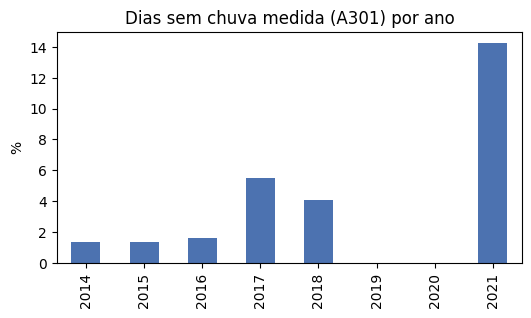

In [5]:
ESTRUTURAL = ["dias_desde_ultimo_alag", "dias_desde_ultimo_alag_estrito", "mare_na_hora_pico_chuva_m", "mare_subindo_na_hora_pico"]
FALHA_ESTACAO = [c for c in df.columns if c.startswith("chuva_")]
LACUNA_JUNCAO = ["area_km2", "lat_centro", "lon_centro", "n_pontos_grade", "alt_media_m", "alt_mediana_m", "alt_min_m", "alt_max_m",
                 "alt_desvio_m", "alt_p10_m", "pct_pontos_abaixo_5m", "pct_area_faixa_marginal", "dist_faixa_media_m", "dist_faixa_min_m", "regional"]

def tipo_ausente(c):
    if c in ESTRUTURAL: return "estrutural"
    if c in FALHA_ESTACAO: return "falha da estacao"
    if c in LACUNA_JUNCAO: return "lacuna de juncao"
    return "outro"

vazio = (df.isna().mean() * 100).round(2)
tab_aus = pd.DataFrame({"vazio_%": vazio[vazio > 0]})
tab_aus["tipo"] = [tipo_ausente(c) for c in tab_aus.index]
tab_aus = tab_aus.sort_values(["tipo", "vazio_%"], ascending=[True, False])
display(tab_aus)
registrar_arquivo(tab_aus, "ausentes.csv")

chuva_falta_ano = df.groupby("ano")["chuva_dia_mm"].apply(lambda s: s.isna().mean() * 100)
fig, ax = plt.subplots(figsize=(6, 3))
chuva_falta_ano.plot(kind="bar", ax=ax, color="#4c72b0")
ax.set_title("Dias sem chuva medida (A301) por ano"); ax.set_ylabel("%"); ax.set_xlabel("")
registrar_fig(fig, "ausentes_chuva_por_ano")
mlflow.log_metric("pct_linhas_sem_chuva", float(df["chuva_dia_mm"].isna().mean() * 100))

**Decisão:** removemos as linhas sem `chuva_dia_mm` (cerca de 3,5%). Os vazios estruturais viram indicador + sentinela, e as lacunas de junção são imputadas pela mediana (calculada **só no treino**, para não vazar informação da validação).

In [6]:
base_ = prep.selecionar_linhas(df)
print(f"linhas antes: {len(df):,} | depois: {len(base_):,} | removidas: {len(df) - len(base_):,} ({100*(1-len(base_)/len(df)):.1f}%)")
print(f"positivos estritos mantidos: {int(base_['alagou_estrito'].sum())} de {int(df['alagou_estrito'].sum())}")

linhas antes: 227,916 | depois: 219,882 | removidas: 8,034 (3.5%)
positivos estritos mantidos: 162 de 162


## 5. Distribuições das variáveis
Interessam duas coisas: a **assimetria** (decide se aplicamos log) e a escala (decide a normalização). Chuva e "dias desde o último evento" são muito assimétricas, com cauda longa — uma minoria de dias concentra os valores extremos.

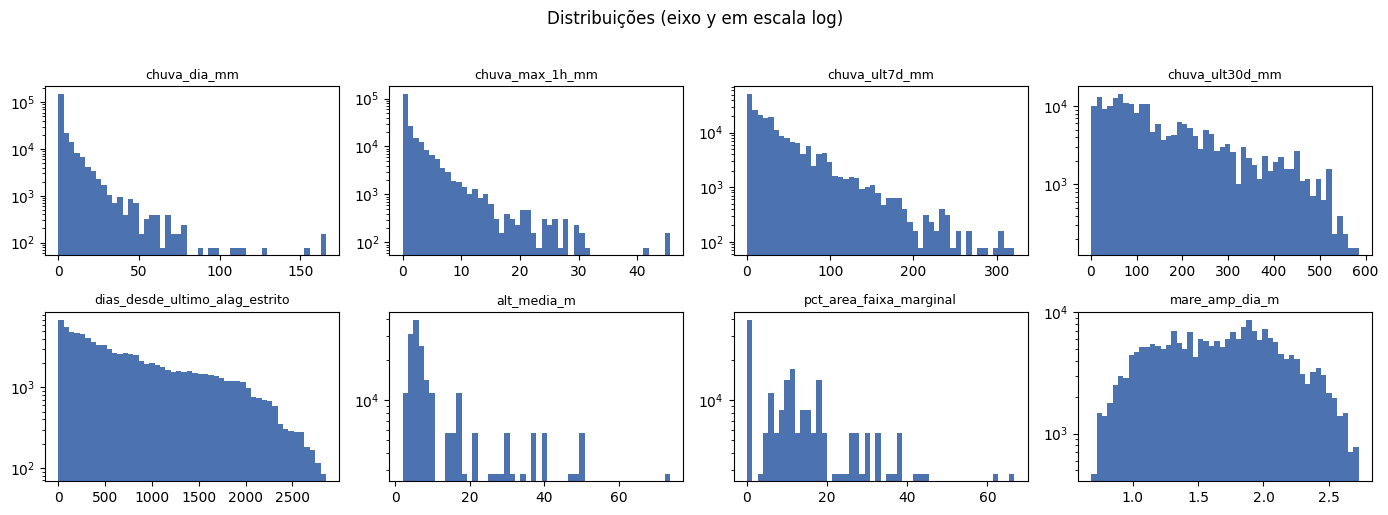

,assimetria (skew)
chuva_dia_mm,5.58
chuva_max_1h_mm,3.90
chuva_ult7d_mm,2.25
chuva_ult30d_mm,1.01
dias_desde_ultimo_alag_estrito,0.77
alt_media_m,1.72
pct_area_faixa_marginal,1.23
mare_amp_dia_m,0.03


In [7]:
cols_dist = ["chuva_dia_mm", "chuva_max_1h_mm", "chuva_ult7d_mm", "chuva_ult30d_mm",
             "dias_desde_ultimo_alag_estrito", "alt_media_m", "pct_area_faixa_marginal", "mare_amp_dia_m"]
fig, axes = plt.subplots(2, 4, figsize=(14, 5))
for ax, c in zip(axes.ravel(), cols_dist):
    ax.hist(base_[c].dropna(), bins=50, color="#4c72b0")
    ax.set_yscale("log"); ax.set_title(c, fontsize=9)
fig.suptitle("Distribuições (eixo y em escala log)", y=1.02)
fig.tight_layout(); registrar_fig(fig, "distribuicoes")

assim = base_[cols_dist].skew().round(2).to_frame("assimetria (skew)")
display(assim)

## 6. O alvo: raridade, tempo e espaço
É a parte mais importante da EDA, porque determina como avaliar os modelos.

,linhas,amplo,estrito,taxa_estrito_%
ano,,,,
2014,28470,84,64,0.225
2015,28470,42,34,0.119
2016,28548,32,30,0.105
2017,28470,29,9,0.032
2018,28470,63,1,0.004
2019,28470,51,17,0.060
2020,28548,10,5,0.018
2021,28470,3,2,0.007



positivos estritos: 162 de 227,916 (0.071%) | amplos: 314
dias distintos com evento estrito: 78 | bairros por dia de evento: mediana 1, max 12
os 10 dias com mais eventos concentram 40% dos positivos
bairros com ao menos 1 evento estrito: 40 de 78 | os 10 maiores concentram 61% dos eventos


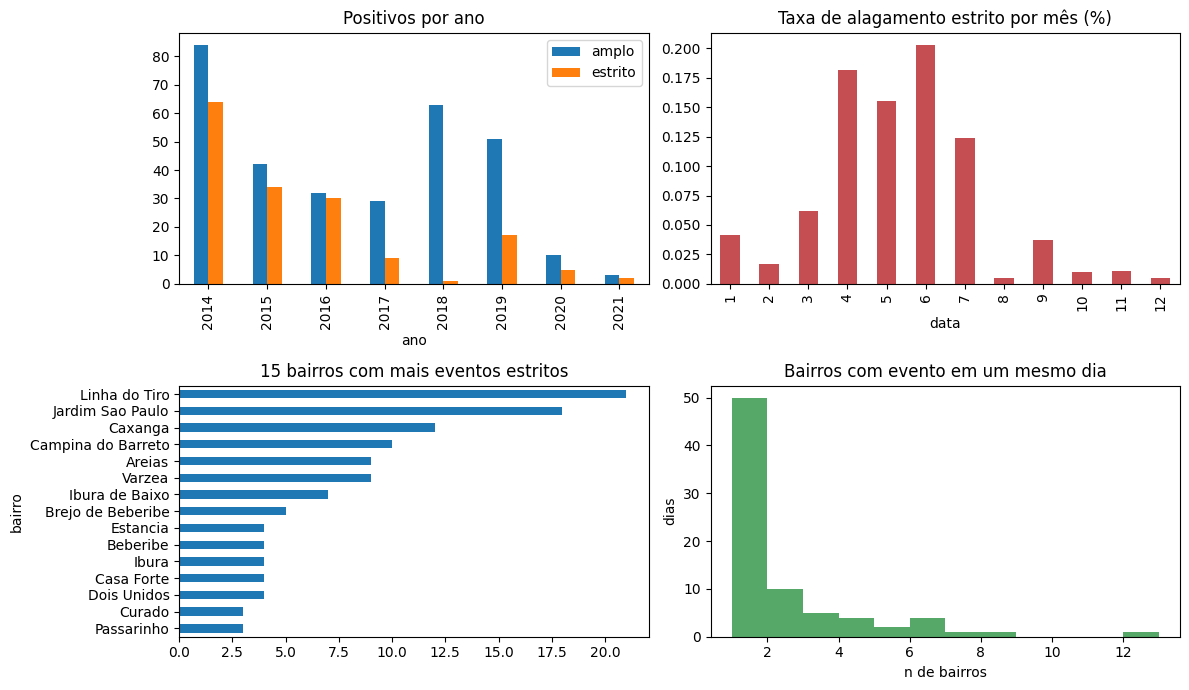

In [8]:
alvo = prep.ALVO_PADRAO
por_ano = df.groupby("ano").agg(linhas=("alagou", "size"), amplo=("alagou", "sum"), estrito=("alagou_estrito", "sum"))
por_ano["taxa_estrito_%"] = (100 * por_ano["estrito"] / por_ano["linhas"]).round(3)
display(por_ano)

n_pos = int(df[alvo].sum())
print(f"\npositivos estritos: {n_pos} de {len(df):,} ({100*n_pos/len(df):.3f}%) | amplos: {int(df['alagou'].sum())}")

ev = df[df[alvo] == 1]
dias_ev = ev.groupby("data").size()
print(f"dias distintos com evento estrito: {len(dias_ev)} | bairros por dia de evento: mediana {dias_ev.median():.0f}, max {dias_ev.max()}")
print(f"os 10 dias com mais eventos concentram {100*dias_ev.sort_values(ascending=False).head(10).sum()/n_pos:.0f}% dos positivos")

top_b = df.groupby("bairro")[alvo].sum().sort_values(ascending=False)
print(f"bairros com ao menos 1 evento estrito: {int((top_b > 0).sum())} de {len(top_b)} | os 10 maiores concentram {100*top_b.head(10).sum()/n_pos:.0f}% dos eventos")

por_mes = df.groupby(df["data"].dt.month).agg(taxa_estrito=(alvo, "mean"), chuva_media=("chuva_dia_mm", "mean"))

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
por_ano[["amplo", "estrito"]].plot(kind="bar", ax=axes[0, 0], title="Positivos por ano")
(por_mes["taxa_estrito"] * 100).plot(kind="bar", ax=axes[0, 1], color="#c44e52", title="Taxa de alagamento estrito por mês (%)")
top_b.head(15).iloc[::-1].plot(kind="barh", ax=axes[1, 0], title="15 bairros com mais eventos estritos")
axes[1, 1].hist(dias_ev.values, bins=range(1, int(dias_ev.max()) + 2), color="#55a868")
axes[1, 1].set_title("Bairros com evento em um mesmo dia"); axes[1, 1].set_xlabel("n de bairros"); axes[1, 1].set_ylabel("dias")
fig.tight_layout(); registrar_fig(fig, "alvo_tempo_espaco")

mlflow.log_metrics({"positivos_estritos": n_pos, "positivos_amplos": int(df["alagou"].sum()),
                    "taxa_positivos_estrito_pct": 100 * n_pos / len(df),
                    "dias_distintos_com_evento": len(dias_ev),
                    "bairros_com_evento": int((top_b > 0).sum())})

**O que isso significa para o projeto:**
1. **Desbalanceamento extremo** (~0,07% positivos): acurácia é inútil; usaremos PR-AUC e recall no topo do ranking.
2. **Eventos agrupados no tempo e no espaço:** poucos dias de tempestade concentram muitos positivos, e poucos bairros concentram a maioria. Linhas de um mesmo dia **não são independentes**, então a validação precisa respeitar o tempo (validação por ano, não embaralhada).
3. **Sazonalidade:** a taxa varia por mês, acompanhando a estação chuvosa.
4. **Mudança de prática de registro:** o número de positivos estritos cai de 64 (2014) para 1 (2018) sem que o clima explique; isso é viés do rótulo, não ausência de alagamentos.

## 7. Relação das variáveis com o alvo
Taxa de alagamento estrito por faixa de cada variável. Se a variável é útil, a taxa deve variar de forma coerente com a física do problema.

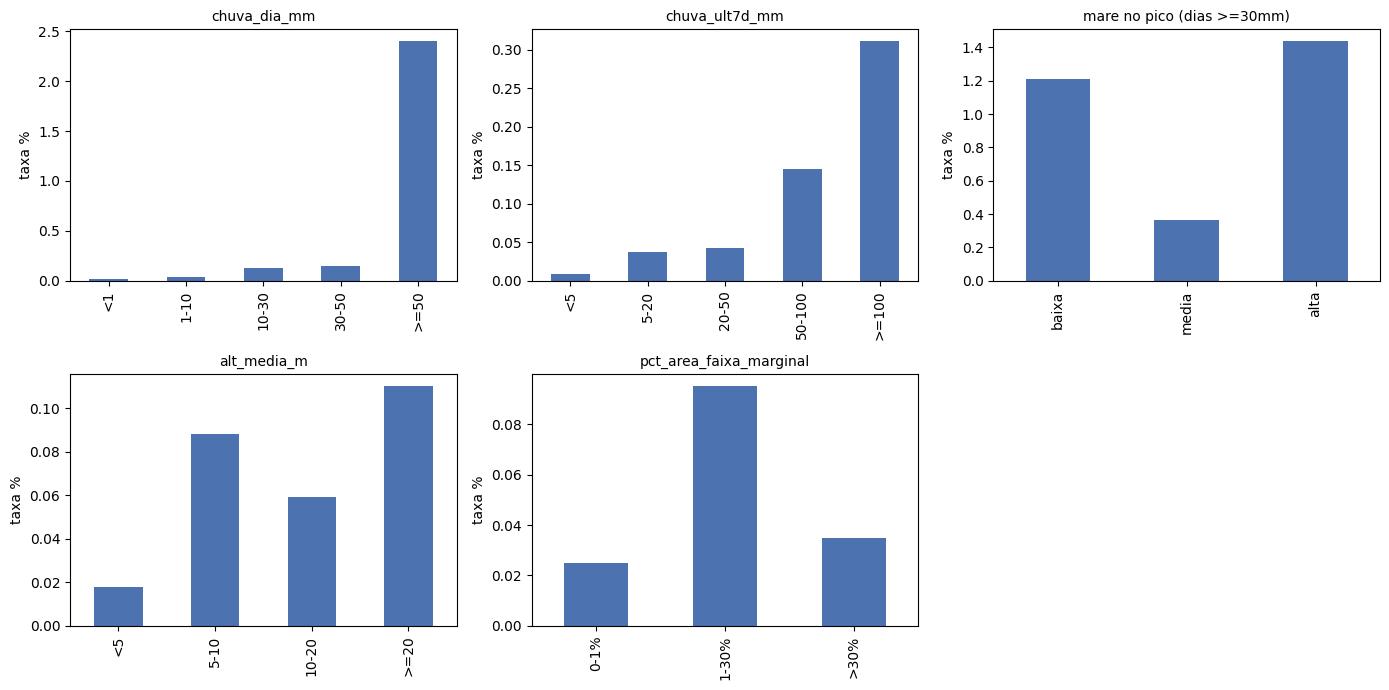


chuva_dia_mm


,linhas,eventos,taxa_%
chuva_dia_mm,,,
<1,115986,25,0.022
1-10,70668,24,0.034
10-30,25584,33,0.129
30-50,4602,7,0.152
>=50,3042,73,2.400



chuva_ult7d_mm


,linhas,eventos,taxa_%
chuva_ult7d_mm,,,
<5,43914,4,0.009
5-20,58110,22,0.038
20-50,60606,26,0.043
50-100,37206,54,0.145
>=100,18018,56,0.311



mare no pico (dias >=30mm)


,linhas,eventos,taxa_%
mare_na_hora_pico_chuva_m,,,
baixa,2886,35,1.213
media,2184,8,0.366
alta,2574,37,1.437



alt_media_m


,linhas,eventos,taxa_%
alt_media_m,,,
<5,50742,9,0.018
5-10,81751,72,0.088
10-20,25371,15,0.059
>=20,50742,56,0.110



pct_area_faixa_marginal


,linhas,eventos,taxa_%
pct_area_faixa_marginal,,,
0-1%,39466,10,0.025
1-30%,140950,134,0.095
>30%,31009,11,0.035


In [9]:
def taxa_por_faixa(d, col, bins, rotulos=None, alvo=prep.ALVO_PADRAO):
    g = pd.cut(d[col], bins, labels=rotulos)
    t = d.groupby(g, observed=False)[alvo].agg(["size", "sum", "mean"])
    t["taxa_%"] = (t["mean"] * 100).round(3)
    return t.drop(columns="mean").rename(columns={"size": "linhas", "sum": "eventos"})

fortes = base_[base_["chuva_dia_mm"] >= 30]
analises = {
    "chuva_dia_mm": taxa_por_faixa(base_, "chuva_dia_mm", prep.FAIXAS_CHUVA, ["<1", "1-10", "10-30", "30-50", ">=50"]),
    "chuva_ult7d_mm": taxa_por_faixa(base_, "chuva_ult7d_mm", [-0.01, 5, 20, 50, 100, 1000], ["<5", "5-20", "20-50", "50-100", ">=100"]),
    "mare no pico (dias >=30mm)": taxa_por_faixa(fortes, "mare_na_hora_pico_chuva_m", [-9, -0.3, 0.3, 9], ["baixa", "media", "alta"]),
    "alt_media_m": taxa_por_faixa(base_, "alt_media_m", [-10, 5, 10, 20, 200], ["<5", "5-10", "10-20", ">=20"]),
    "pct_area_faixa_marginal": taxa_por_faixa(base_, "pct_area_faixa_marginal", [-0.01, 1, 30, 100], ["0-1%", "1-30%", ">30%"]),
}
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, (nome, t) in zip(axes.ravel(), analises.items()):
    t["taxa_%"].plot(kind="bar", ax=ax, color="#4c72b0"); ax.set_title(nome, fontsize=10); ax.set_ylabel("taxa %"); ax.set_xlabel("")
axes.ravel()[-1].axis("off")
fig.tight_layout(); registrar_fig(fig, "relacao_com_alvo")
for nome, t in analises.items():
    print(f"\n{nome}"); display(t)

**Leitura:** a chuva do dia tem comportamento de **limiar** (a taxa salta acima de ~50 mm). A faixa marginal separa bairros como esperado. A maré, condicionada a dias de chuva forte, não mostra efeito monotônico claro. A altitude média tem sinal contrário ao esperado — um alerta de que é um mau indicador do risco hidrológico (o que importa é a altitude relativa à drenagem).

### Poder preditivo univariado
Para cada variável: ROC-AUC e PR-AUC usando-a **sozinha** como pontuação (orientada na direção que funciona). Serve para priorizar variáveis e detectar suspeitas — por exemplo, variáveis de calendário com poder alto são sinal de "impressão digital de data" (identificam dias de tempestade específicos), não de causalidade.

,variavel,ROC-AUC (orientado),sinal,PR-AUC
0,chuva_dia_mm,0.8376,+,0.0210
1,chuva_max_1h_mm,0.8203,+,0.0080
2,chuva_d1_mm,0.7857,+,0.0081
3,chuva_ult3d_mm,0.7797,+,0.0047
4,chuva_ult7d_mm,0.7727,+,0.0040
5,chuva_ult30d_mm,0.7648,+,0.0025
6,dias_desde_ultimo_alag,0.7624,-,0.0099
7,chuva_ult15d_mm,0.7577,+,0.0031
8,dias_desde_ultimo_alag_estrito,0.7545,-,0.0162
9,n_alag_estrito_bairro_365d,0.7241,+,0.0033


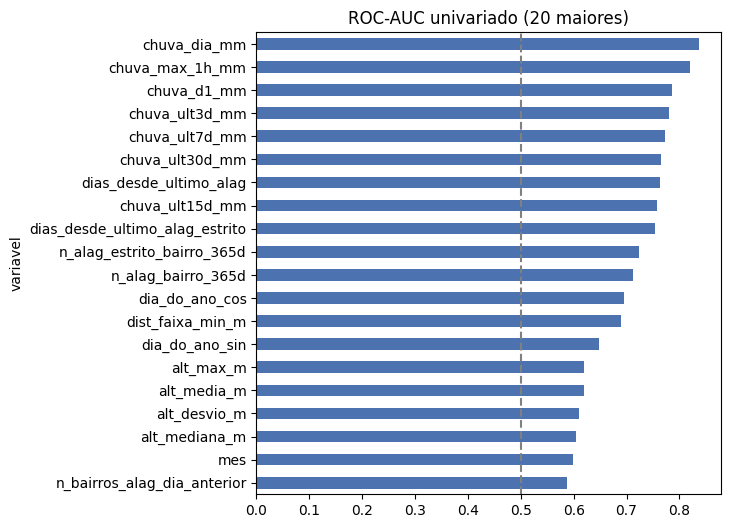

In [10]:
cand = [c for c in base_.columns if c not in prep.EXCLUIR]
y_ = base_[prep.ALVO_PADRAO].values
linhas = []
for c in cand:
    x = base_[c].fillna(base_[c].median())
    auc = roc_auc_score(y_, x)
    score = x if auc >= 0.5 else -x
    linhas.append({"variavel": c, "ROC-AUC (orientado)": max(auc, 1 - auc), "sinal": "+" if auc >= 0.5 else "-",
                   "PR-AUC": average_precision_score(y_, score)})
poder = pd.DataFrame(linhas).sort_values("ROC-AUC (orientado)", ascending=False).reset_index(drop=True)
display(poder.round(4))
registrar_arquivo(poder.set_index("variavel"), "poder_univariado.csv")
mlflow.log_metric("melhor_auc_univariada", float(poder.iloc[0]["ROC-AUC (orientado)"]))

fig, ax = plt.subplots(figsize=(6, 6))
poder.head(20).iloc[::-1].plot(kind="barh", x="variavel", y="ROC-AUC (orientado)", ax=ax, legend=False, color="#4c72b0")
ax.axvline(0.5, color="gray", ls="--"); ax.set_title("ROC-AUC univariado (20 maiores)")
registrar_fig(fig, "poder_univariado")

## 8. Correlação e redundância
Variáveis muito correlacionadas (as janelas de chuva; as medidas de altitude) carregam informação repetida. Isso não prejudica árvores, mas deixa a regressão logística instável e **divide a importância** entre elas na interpretação.

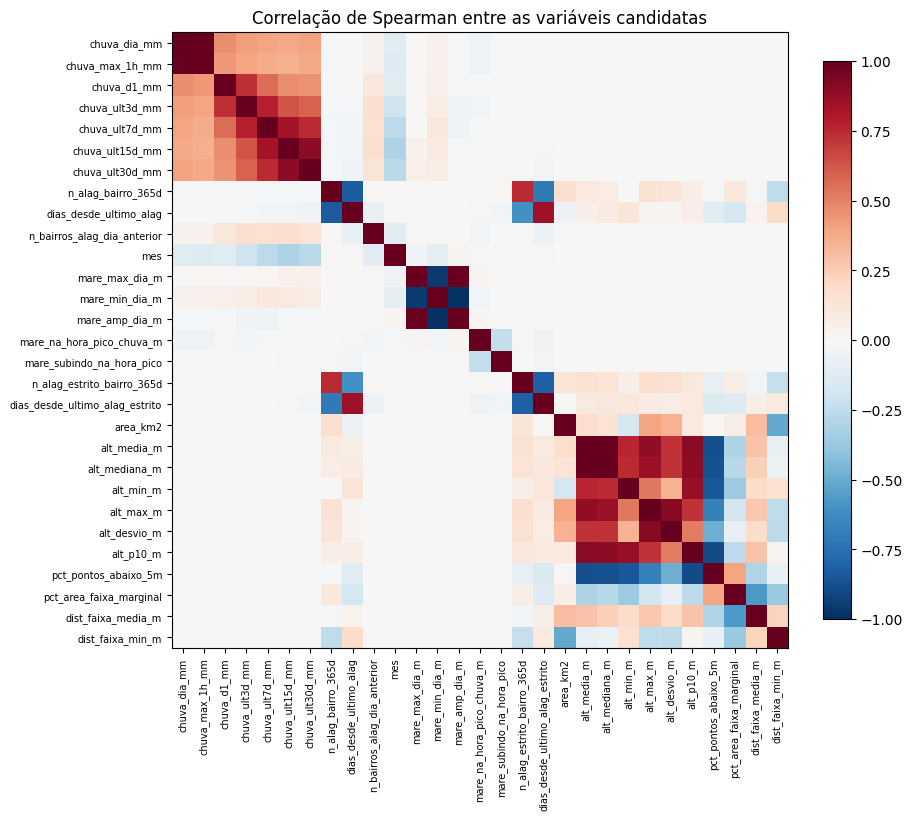

pares com |rho| >= 0.9: 7


,a,b,rho
0,alt_media_m,alt_mediana_m,0.990
1,mare_max_dia_m,mare_amp_dia_m,0.990
2,mare_min_dia_m,mare_amp_dia_m,-0.988
3,chuva_dia_mm,chuva_max_1h_mm,0.985
4,mare_max_dia_m,mare_min_dia_m,-0.956
5,alt_max_m,alt_desvio_m,0.908
6,alt_media_m,alt_p10_m,0.905


In [11]:
feats_A = prep.lista_features(base_.columns, "A")
corr = base_[feats_A].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index, fontsize=7)
fig.colorbar(im, ax=ax, fraction=0.04); ax.set_title("Correlação de Spearman entre as variáveis candidatas")
registrar_fig(fig, "correlacao")

iu = np.triu_indices_from(corr, k=1)
pares = pd.DataFrame({"a": corr.index[iu[0]], "b": corr.columns[iu[1]], "rho": corr.values[iu]})
pares = pares[pares["rho"].abs() >= 0.9].sort_values("rho", key=lambda s: s.abs(), ascending=False).reset_index(drop=True)
print(f"pares com |rho| >= 0.9: {len(pares)}")
display(pares.round(3))
mlflow.log_metric("pares_correlacao_alta", len(pares))

**Decisão:** manter todas por ora. Os grupos redundantes (altitude, chuva acumulada) serão avaliados na etapa de modelagem; se a regressão logística ficar instável, reduzimos por grupo. Para a interpretação, a importância deve ser lida **por grupo** de variáveis.

## 9. Distribuição espacial
Os eventos se concentram em poucos bairros, como mostra o mapa (posição aproximada do centro de cada bairro; tamanho proporcional ao número de eventos estritos).

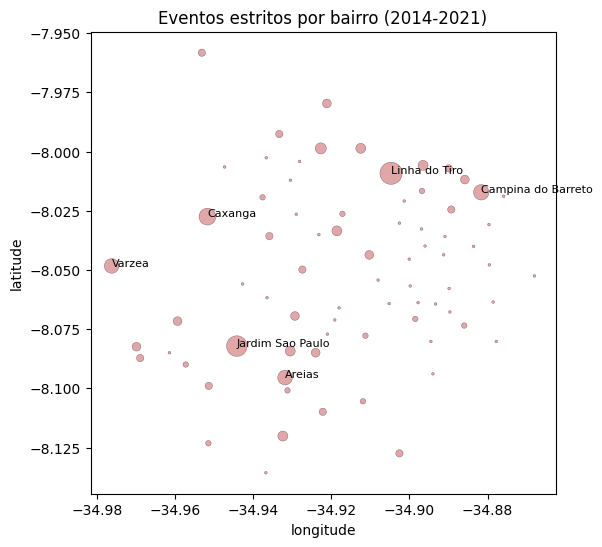

In [12]:
geo = df.groupby("bairro").agg(lat=("lat_centro", "first"), lon=("lon_centro", "first"), eventos=(prep.ALVO_PADRAO, "sum")).dropna()
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(geo["lon"], geo["lat"], s=geo["eventos"] * 12 + 4, alpha=0.5, color="#c44e52", edgecolor="k", linewidth=0.3)
for nome, r in geo.sort_values("eventos", ascending=False).head(6).iterrows():
    ax.annotate(nome, (r["lon"], r["lat"]), fontsize=8)
ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.set_title("Eventos estritos por bairro (2014-2021)")
registrar_fig(fig, "mapa_eventos")

## 10. Decisões de preparação e justificativas

| # | Decisão | Justificativa | Evidência |
|---|---|---|---|
| 1 | Remover linhas sem `chuva_dia_mm` (~3,5%) | Sem a variável dominante não há o que prever; imputar chuva inventaria dados | Seção 4 |
| 2 | Excluir `n_registros_alag*` | Contam o alvo do próprio dia (**vazamento**) | Dicionário |
| 3 | Excluir `bairro`, `regional`, `lat/lon_centro` como entrada | Levariam o modelo a **decorar lugares**; o "onde" entra de forma controlada (decisão 8) | Seção 6 |
| 4 | Excluir `fase_lunar`, `sizigia`, `dia_do_ano_*` | Quase identificam um dia específico; como os eventos se agrupam em poucos dias de tempestade, o modelo **decora datas** e não generaliza | Seção 7 e experimentos de modelagem |
| 5 | Vazios estruturais → indicador + sentinela (3650 dias) | O vazio **tem significado** ("nunca houve evento"); imputar mediana apagaria isso | Seção 4 |
| 6 | `log1p` em chuvas e "dias desde" | Distribuições com cauda longa (skew alto); o log aproxima da escala em que a relação é mais regular | Seção 5 |
| 7 | Imputação pela mediana (só no treino) e padronização (só para modelos lineares/KNN) | Lacunas de junção são poucas (≤5%); a padronização é necessária à regressão logística e irrelevante às árvores. Ajustar só no treino evita vazamento | Seção 4 |
| 8 | Codificar o bairro como **propensão histórica** em vez de one-hot | 78 categorias com ~2 eventos cada levam a decorar; a propensão é um número único, suavizado, e calculada sem o próprio ano para não ler o rótulo | Seção 11 |
| 9 | Dois cenários de variáveis: **A** (chuva do dia conhecida) e **B** (sem ela) | O sistema real só terá a chuva do dia com um pluviômetro ou previsão; B mede a dependência disso | Dicionário |
| 10 | Divisão por **ano**, não aleatória | Eventos agrupados por tempestade e viés de registro variável no tempo: embaralhar vazaria dias do mesmo evento entre treino e teste | Seção 6 |

## 11. Aplicando e verificando a preparação
Demonstramos o `Preparador` (transformação ajustada **só no treino**) e a codificação do bairro por propensão, usando 2019 como ano de validação.

features cenario A: 29 | cenario B: 25
matriz treino (191412, 32) | validacao (28470, 32) | NaN apos preparacao: treino 0, validacao 0
colunas novas criadas: ['dias_desde_ultimo_alag_nunca', 'dias_desde_ultimo_alag_estrito_nunca', 'sem_chuva_no_dia']


,skew antes,skew depois (log)
chuva_dia_mm,5.40,0.94
chuva_max_1h_mm,4.01,1.05
chuva_ult7d_mm,2.15,-0.45
chuva_ult30d_mm,1.06,-0.70


,mean,std
chuva_dia_mm,0.0,1.0
chuva_max_1h_mm,-0.0,1.0
chuva_d1_mm,0.0,1.0
chuva_ult3d_mm,0.0,1.0
chuva_ult7d_mm,-0.0,1.0
chuva_ult15d_mm,0.0,1.0
chuva_ult30d_mm,0.0,1.0
n_alag_bairro_365d,0.0,1.0


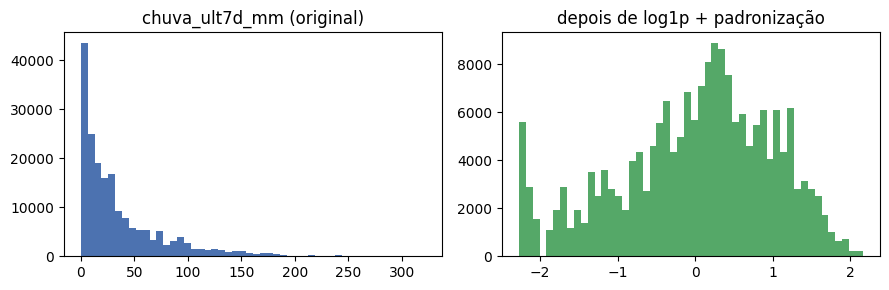

In [13]:
FEATURES_A = prep.lista_features(base_.columns, "A")
FEATURES_B = prep.lista_features(base_.columns, "B")
print(f"features cenario A: {len(FEATURES_A)} | cenario B: {len(FEATURES_B)}")

treino = base_[base_["ano"] != 2019]; valid = base_[base_["ano"] == 2019]
prepar = prep.Preparador(log=True, escala=True, imputar=True).fit(treino[FEATURES_A])
Xtr = prepar.transform(treino[FEATURES_A]); Xva = prepar.transform(valid[FEATURES_A])
print(f"matriz treino {Xtr.shape} | validacao {Xva.shape} | NaN apos preparacao: treino {int(Xtr.isna().sum().sum())}, validacao {int(Xva.isna().sum().sum())}")
print("colunas novas criadas:", [c for c in Xtr.columns if c not in FEATURES_A])

comp = pd.DataFrame({"skew antes": treino[cols_dist[:4]].skew(), "skew depois (log)": Xtr[cols_dist[:4]].skew()}).round(2)
display(comp)
display(Xtr.describe().loc[["mean", "std"]].T.round(2).head(8))

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].hist(treino["chuva_ult7d_mm"].dropna(), bins=50, color="#4c72b0"); axes[0].set_title("chuva_ult7d_mm (original)")
axes[1].hist(Xtr["chuva_ult7d_mm"], bins=50, color="#55a868"); axes[1].set_title("depois de log1p + padronização")
fig.tight_layout(); registrar_fig(fig, "antes_depois_log")

### A propensão do bairro: por que calcular "sem o próprio ano"
Se a propensão de uma linha de treino usar os eventos do **próprio ano**, ela contém a resposta e parece mais informativa do que realmente é. A comparação abaixo mede isso: a versão ingênua deve parecer melhor no treino do que a honesta, mas **só a honesta** se parece com o que acontece em dados novos (validação).

In [14]:
alvo = prep.ALVO_PADRAO
anos_tr = sorted(treino["ano"].unique())
tabela = prep.tabela_propensao(base_, alvo, anos_tr)
ingenua = prep.aplicar_propensao(treino, tabela)                         # inclui o proprio ano (vaza)
honesta = prep.propensao_treino(base_, alvo, anos_tr).loc[treino.index]  # sem o proprio ano
na_validacao = prep.aplicar_propensao(valid, tabela)                     # como seria em dados novos

auc = {"treino, ingênua (vaza)": roc_auc_score(treino[alvo], ingenua),
       "treino, sem o próprio ano": roc_auc_score(treino[alvo], honesta),
       "validação (2019)": roc_auc_score(valid[alvo], na_validacao)}
display(pd.Series(auc, name="ROC-AUC da propensão sozinha").round(3).to_frame())
mlflow.log_metrics({"auc_propensao_ingenua_treino": auc["treino, ingênua (vaza)"],
                    "auc_propensao_honesta_treino": auc["treino, sem o próprio ano"],
                    "auc_propensao_validacao_2019": auc["validação (2019)"]})

,ROC-AUC da propensão sozinha
"treino, ingênua (vaza)",0.875
"treino, sem o próprio ano",0.800
validação (2019),0.752


## 12. Saídas da preparação e registro final
Gravamos o dataset de modelagem (linhas com chuva medida, só as colunas necessárias), as listas de variáveis e as decisões. Esses arquivos são a **interface** entre este notebook e o notebook de treino — e, mais adiante, a saída que o DAG do Airflow disponibilizará para o treinamento.

In [15]:
colunas_saida = ["bairro", "data", "ano", "alagou", "alagou_estrito"] + FEATURES_A
saida = RAIZ / "processed" / "dataset_modelagem.csv"
base_[colunas_saida].to_csv(saida, index=False)

listas = {"alvo_principal": prep.ALVO_PADRAO, "alvo_secundario": "alagou",
          "features_A": FEATURES_A, "features_B": FEATURES_B,
          "excluidas": prep.EXCLUIR, "excluidas_impressao_digital_de_data": prep.DATAS_IMPRESSAO_DIGITAL,
          "cenario_B_remove": prep.DEPENDEM_CHUVA_DO_DIA,
          "anos_para_validacao": sorted(int(a) for a in base_["ano"].unique())}
registrar_arquivo(listas, "listas_de_variaveis.json")

decisoes = {"linhas_removidas_sem_chuva": int(len(df) - len(base_)), "log1p": prep.COLS_LOG + prep.COLS_DIAS,
            "sentinela_dias_sem_evento": prep.DIAS_SEM_EVENTO, "imputacao": "mediana (ajustada so no treino)",
            "padronizacao": "z-score (so modelos lineares/KNN)", "codificacao_bairro": "propensao historica, sem o proprio ano",
            "validacao": "por ano (leave-one-year-out)", "dataset_sha256_16": sha}
registrar_arquivo(decisoes, "decisoes_preparacao.json")

mlflow.log_params({"n_features_A": len(FEATURES_A), "n_features_B": len(FEATURES_B),
                   "linhas_modelagem": len(base_), "anos_cv": len(base_["ano"].unique())})
mlflow.log_artifact(str(RAIZ / "src" / "preparacao.py"), artifact_path="codigo")
print(f"gravado: {saida.name} ({len(base_):,} linhas, {len(colunas_saida)} colunas)")
print(f"run MLflow: {run.info.run_id}")
mlflow.end_run()

gravado: dataset_modelagem.csv (219,882 linhas, 34 colunas)
run MLflow: 5bc45d6bf0884a0fb1139fb990d3b46f


## 13. Como isto vira o pipeline (Airflow)
Cada etapa deste trabalho já existe como script e mapeia para uma tarefa do DAG:

| Tarefa do DAG | Código atual | Entrada → saída |
|---|---|---|
| `ingestao` | `baixar_dados.py`, `baixar_local.py`; leitura MQTT do embarcado | fontes → `raw/` e banco |
| `preparacao_base` | `parse_defesa_civil.py`, `mare_harmonica.py`, `build_dataset.py`, `features_local.py` | `raw/` → `dataset_ml_bairro_dia_completo.csv` |
| `qualidade` | `preparacao.verificar_qualidade` | dataset → relatório e falha do DAG se houver duplicatas/valores impossíveis |
| `disponibilizacao` | este notebook (`selecionar_linhas`, `lista_features`) | dataset → `dataset_modelagem.csv` + `listas_de_variaveis.json` |
| `treino` (próximo notebook) | modelos + MLflow | `dataset_modelagem.csv` → modelo registrado |

**Próximo notebook (02):** baseline, comparação de ao menos 3 modelos, otimização de hiperparâmetros, validação cruzada e análise de overfitting, tudo registrado no MLflow.